# Analizar normalidad en variables

Analiza la normalidad en la variable avg_sleep_hours del dataset:

https://www.kaggle.com/datasets/aamir28/student-sleep-screen-time-and-academic-performance

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import shapiro, normaltest, probplot, boxcox
from sklearn.preprocessing import PowerTransformer

In [48]:
# Cargamos el dataset
df = pd.read_csv("student_sleep_screen_time_academic_performance.csv")

## Calcula la media, mediana y desviación típica.

In [ ]:
print('Análisis basico')
df['avg_sleep_hours_weekday'].describe()

Análisis basico


count    500.000000
mean       6.608200
std        1.435784
min        1.500000
25%        5.700000
50%        6.600000
75%        7.700000
max       10.500000
Name: avg_sleep_hours_weekday, dtype: float64

## Calcula el sesgo, la curtosis, y comenta el resultado.

#### Sesgo

In [52]:
sesgo = df['avg_sleep_hours_weekday'].skew()

print(sesgo)

-0.284175876714235


#### Curtosis

In [53]:
curtosis = df['avg_sleep_hours_weekday'].kurtosis()

print(curtosis)

-0.08881772208593386


## Resultado

Primero comentaré sobre el **sesgo**. 

Podemos ver que tiene un *valor menor que 0*, lo que nos hace entender que tiene un sesgo negativo, ubicado a la izquierda (o cola izquierda).

Sobre la **curtosis**.

Como también es *muy cercano a 0*, podemos decir que es una curtosis mesocurtica, la cola es ligera y posiblemente tenga una distribución uniforme.

## Dibuja el histograma, y sobre el la distribución normal teórica.

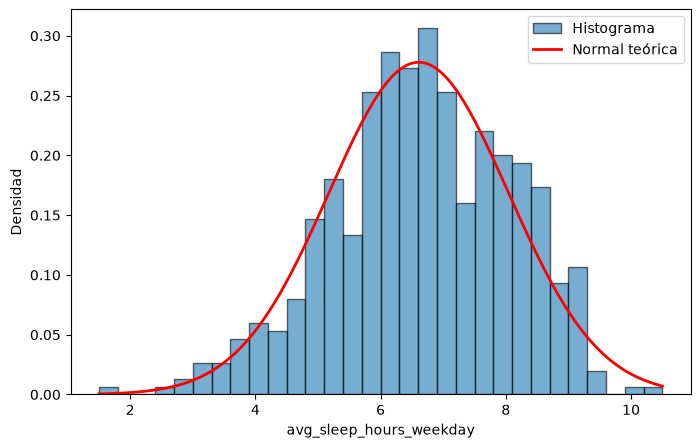

In [54]:
data = df['avg_sleep_hours_weekday'].dropna()

plt.figure(figsize=(8, 5))
plt.hist(data, bins=30, density=True, alpha=0.6, edgecolor='black', label='Histograma')

x = np.linspace(data.min(), data.max(), 200)
plt.plot(x, stats.norm.pdf(x, mean_value, std_value), 'r', linewidth=2, label='Normal teórica')

plt.xlabel('avg_sleep_hours_weekday')
plt.ylabel('Densidad')
plt.legend()
plt.show()

## Realiza el test Shapiro-Wilk y comenta el resultado.

In [55]:
W, p = shapiro(df['avg_sleep_hours_weekday'].dropna())
resultado = '✅ Compatible' if p > 0.05 else '❌ NO normal'
print(f"{'avg_sleep_hours_weekday':<25} W={W:.4f}  p={p:.4f}  {resultado}")

avg_sleep_hours_weekday   W=0.9912  p=0.0046  ❌ NO normal


Shapiro-Wilk: W = 0.9912 y p = 0.0046 < 0.05, así que se rechaza la normalidad. W es cercano a 1, por lo que la desviación es pequeña.

## Dibuja el gráfico Q-Q, y comenta el resultado.

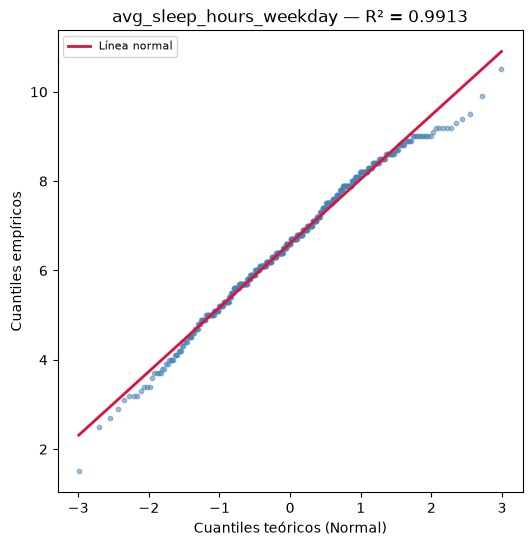

In [56]:
res = probplot(df['avg_sleep_hours_weekday'].dropna(), dist="norm", plot=None)
teoricos = res[0][0]
empiricos = res[0][1]
slope, intercept, r = res[1]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(teoricos, empiricos, s=10, alpha=0.5, color='steelblue')
x_line = np.array([teoricos.min(), teoricos.max()])
ax.plot(x_line, slope * x_line + intercept, 'crimson', linewidth=2, label='Línea normal')
ax.set_title(f'avg_sleep_hours_weekday — R² = {r**2:.4f}')
ax.set_xlabel('Cuantiles teóricos (Normal)')
ax.set_ylabel('Cuantiles empíricos')
ax.legend(fontsize=8)
plt.show()

Podemos ver que los puntos se separan en los extremos menos en el centro. Sobretodo se separan en la cola izquierda, como comentamos al principio, hay un sesgo en ese lado. No es una distribuición normal pero se acerca a serlo.

## Recomienda una transformación (o no).

No recomiendo una trasnformación, porque la distribuición no presenta desviaciones muy exageradas y esta está cerca de ser una distribuición normal. Si los valores distasen mucho entre sí, podriamos utilizar una transformación logaritmica.